# 02 · Paid Search two-arm geo dark-out & brand cannibalisation

**Business question.** How much paid-search volume is truly incremental — and how much do branded keywords just buy clicks
that organic search would have delivered anyway?

**Design.** In the Northvale region the pipeline picks, from design-period data only:
* an **all-search-off** arm (branded + non-branded paused),
* a **branded-only-off** arm,
* a **control** county (ratio-DiD comparator), and
* a pool of **BAU donors** (synthetic control, BSTS and fixed-effects DiD).

Outcomes are normalised **per capita**; the 6-week dark-out is read with four estimators and triangulated; **organic
recapture** of lost paid conversions measures cannibalisation. Ground truth comes from the generator.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from incrlab.config import get_config
cfg = get_config()
print("seed", cfg.seed, "| small", cfg.small)
def show(name, module, width=900):
    display(Image(filename=str(ROOT / "reports" / "figures" / module / f"{name}.png"), width=width))

seed 20260 | small False


In [2]:
from incrlab.search import get_settings
from incrlab.search import design as D, panel as P
from incrlab.simulate import get_world, realize
s = get_settings(cfg)
world = get_world(cfg)
bau_panel = P.build_county_panel(realize(world, with_truth=False).panels["county_weekly"], s.region)
des = D.run_design(bau_panel, world.geo.zips, world.geo.counties, s)
design = des["design"]
print("design uses weeks <=", s.design_end)
{k: design[k] for k in ("all_search", "branded_only", "control")} | {"n_bau_donors": len(design["bau_donors"])}

design uses weeks <= 78


{'all_search': ['NV-C08', 'NV-C14'],
 'branded_only': ['NV-C05', 'NV-C12'],
 'control': ['NV-C11'],
 'n_bau_donors': 9}

## 1. County MDE and arm selection
Each candidate (single county or adjacent pair) gets a per-capita synthetic control fit on the **same metric** used in the
readout, an injected +5/10/15% recovery check, and a minimum detectable effect. Arms are assigned to maximise expected power
subject to the recovery gate; the control is the best-matching remaining county.

In [3]:
des["mde_table"].head(12)

,unit,label,counties,n_counties,pop,weekly_rated,pre_rel_rmse,sigma_gap,rho,oos_rel_rmse,mde,n_donors_used,max_weight,natural_gap,weights,detected_5,abs_err_5,detected_10,abs_err_10,detected_15,abs_err_15,mean_abs_err,sigma_gap_sales,mde_sales,power_all_prior,power_brand_prior
0,NV-C05+NV-C12,Fernhollow + Northcote,"[NV-C05, NV-C12]",2,"374,499.0000",162.5000,0.0934,0.1001,0.0257,0.0633,0.1101,7,0.4440,-0.0333,"{'NV-C02': 0.101, 'NV-C06': 0.049, 'NV-C07': 0...",0.0483,0.0017,0.0967,0.0033,0.1450,0.0050,0.0033,0.2507,0.2918,0.3878,0.1464
1,NV-C08,Pinecrest,[NV-C08],1,"189,031.0000",101.0192,0.1027,0.1032,0.0000,0.0802,0.1106,8,0.2609,0.0281,"{'NV-C01': 0.175, 'NV-C02': 0.101, 'NV-C03': 0...",0.0514,0.0014,0.1028,0.0028,0.1542,0.0042,0.0028,0.3247,0.3480,0.3700,0.1436
2,NV-C08+NV-C14,Pinecrest + Hearthstone,"[NV-C08, NV-C14]",2,"409,744.0000",177.1346,0.0745,0.1067,0.0000,0.1067,0.1144,8,0.4997,0.0537,"{'NV-C01': 0.117, 'NV-C02': 0.156, 'NV-C03': 0...",0.0527,0.0027,0.1054,0.0054,0.1581,0.0081,0.0054,0.2358,0.2528,0.3922,0.1462
3,NV-C07+NV-C12,Valebrook + Northcote,"[NV-C07, NV-C12]",2,"195,441.0000",93.2115,0.1235,0.1354,0.0000,0.1354,0.1451,7,0.3535,-0.0186,"{'NV-C02': 0.353, 'NV-C04': 0.126, 'NV-C05': 0...",0.0491,0.0009,0.0981,0.0019,0.1472,0.0028,0.0019,0.3045,0.3264,0.2913,0.1286
4,NV-C03+NV-C09,Goldmoor + Yarrow,"[NV-C03, NV-C09]",2,"344,600.0000",135.8654,0.1164,0.1373,0.0258,0.1373,0.1510,5,0.6433,-0.0743,"{'NV-C01': 0.053, 'NV-C04': 0.185, 'NV-C06': 0...",0.0463,0.0037,0.0926,0.0074,0.1389,0.0111,0.0074,0.2605,0.2792,0.2971,0.1293
5,NV-C07+NV-C14,Valebrook + Hearthstone,"[NV-C07, NV-C14]",2,"299,509.0000",107.5769,0.1130,0.1215,0.1623,0.1215,0.1534,7,0.6500,0.0732,"{'NV-C01': 0.025, 'NV-C02': 0.135, 'NV-C05': 0...",0.0537,0.0037,0.1073,0.0073,0.1610,0.0110,0.0073,0.2607,0.2795,0.2932,0.1286
6,NV-C09,Yarrow,[NV-C09],1,"260,732.0000",92.5577,0.1387,0.1333,0.1046,0.1234,0.1587,5,0.8679,-0.0619,"{'NV-C01': 0.005, 'NV-C03': 0.023, 'NV-C06': 0...",0.0469,0.0031,0.0938,0.0062,0.1407,0.0093,0.0062,0.3060,0.3281,0.2690,0.1249
7,NV-C05,Fernhollow,[NV-C05],1,"257,854.0000",100.7500,0.1323,0.1373,0.0894,0.1029,0.1610,6,0.6034,-0.0255,"{'NV-C06': 0.05, 'NV-C07': 0.163, 'NV-C10': 0....",0.0487,0.0013,0.0975,0.0025,0.1462,0.0038,0.0025,0.3281,0.4179,0.2490,0.1220
8,NV-C02,Coldwater Vale,[NV-C02],1,"613,249.0000",319.7692,0.0882,0.1448,0.0428,0.1448,0.1620,10,0.2130,0.0820,"{'NV-C04': 0.028, 'NV-C05': 0.058, 'NV-C06': 0...",0.0541,0.0041,0.1082,0.0082,0.1623,0.0123,0.0082,0.1949,0.2167,0.3185,0.1323
9,NV-C12,Northcote,[NV-C12],1,"116,645.0000",61.7500,0.1443,0.1523,0.0000,0.1230,0.1632,7,0.3039,-0.0379,"{'NV-C02': 0.304, 'NV-C04': 0.186, 'NV-C06': 0...",0.0481,0.0019,0.0962,0.0038,0.1443,0.0057,0.0038,0.4284,0.4592,0.2413,0.1208


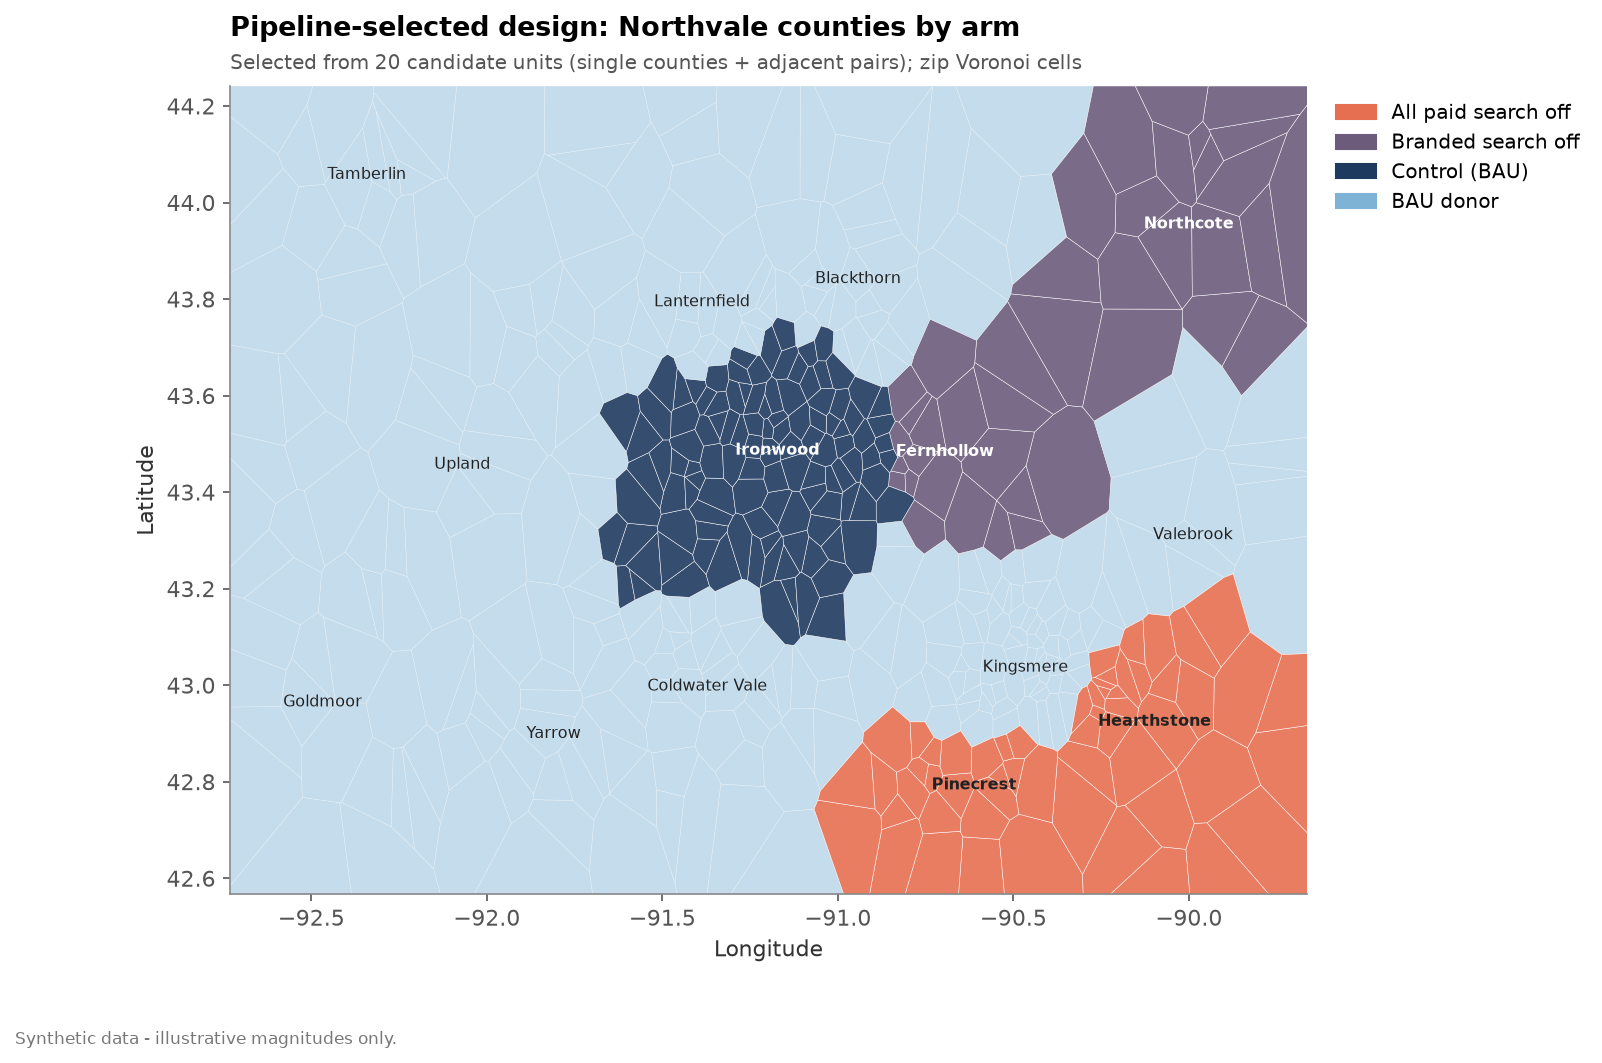

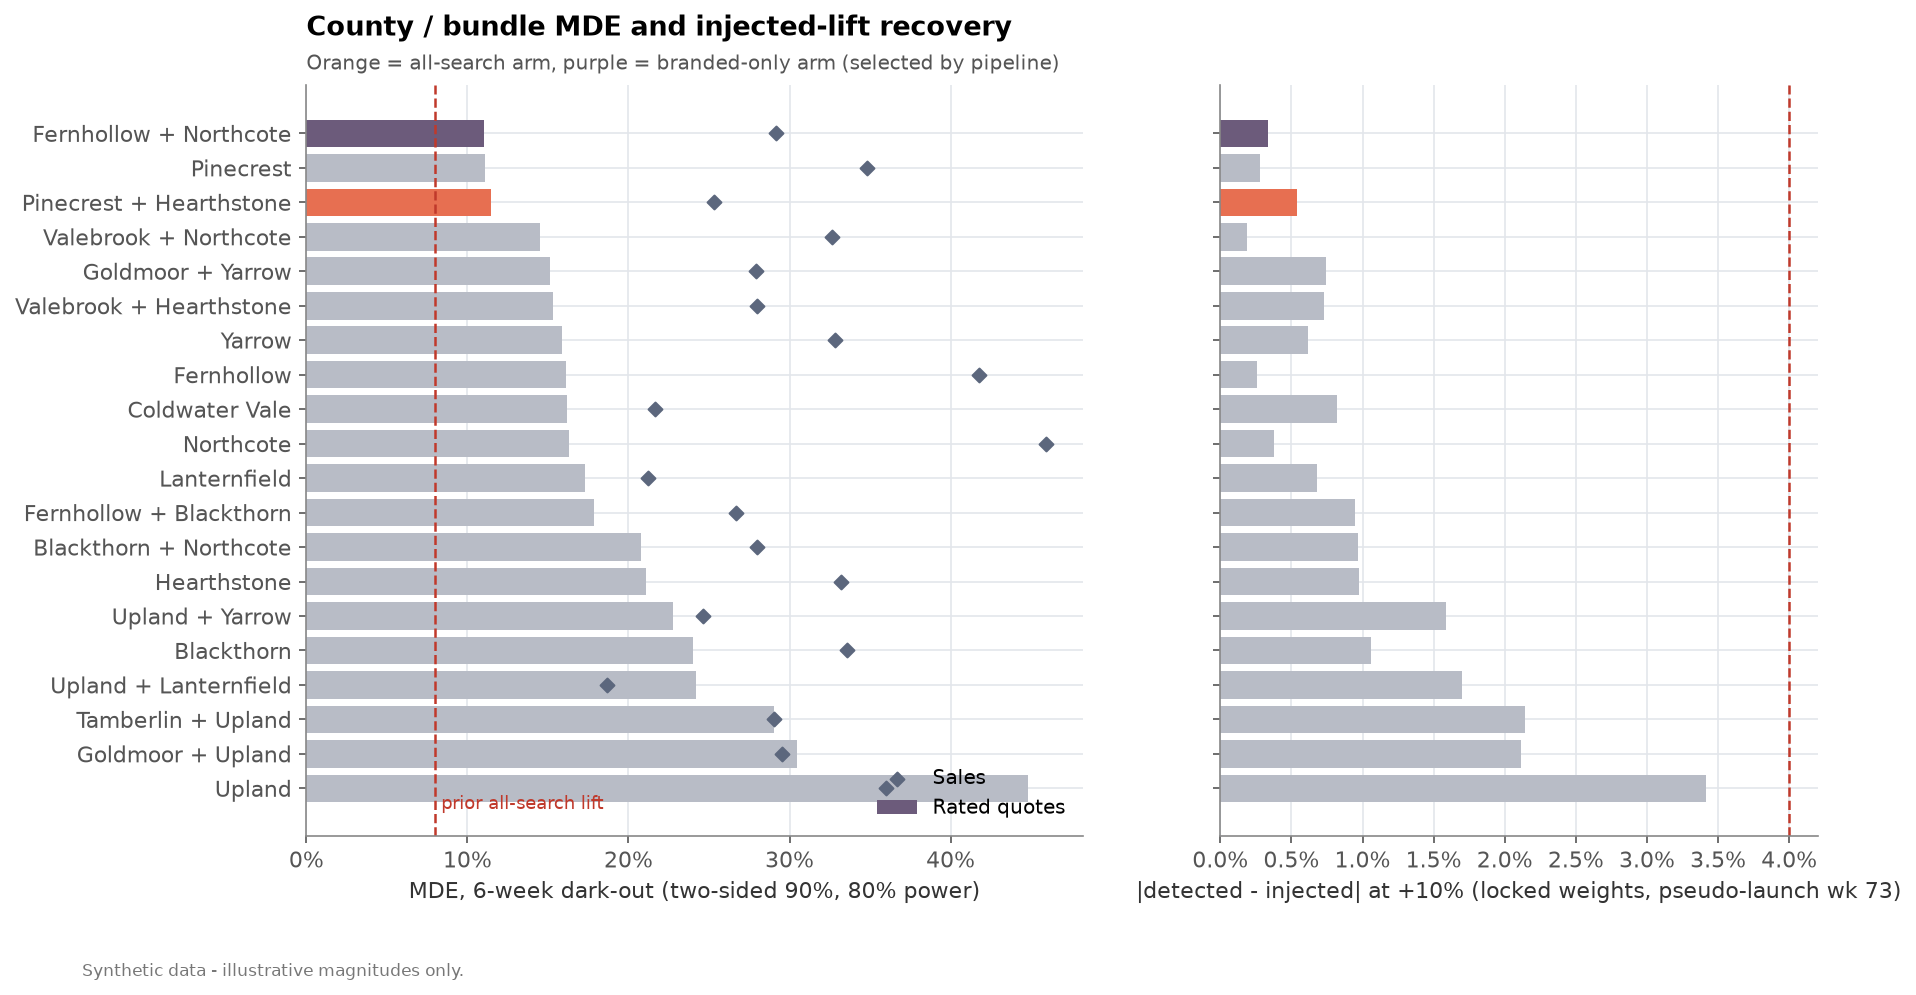

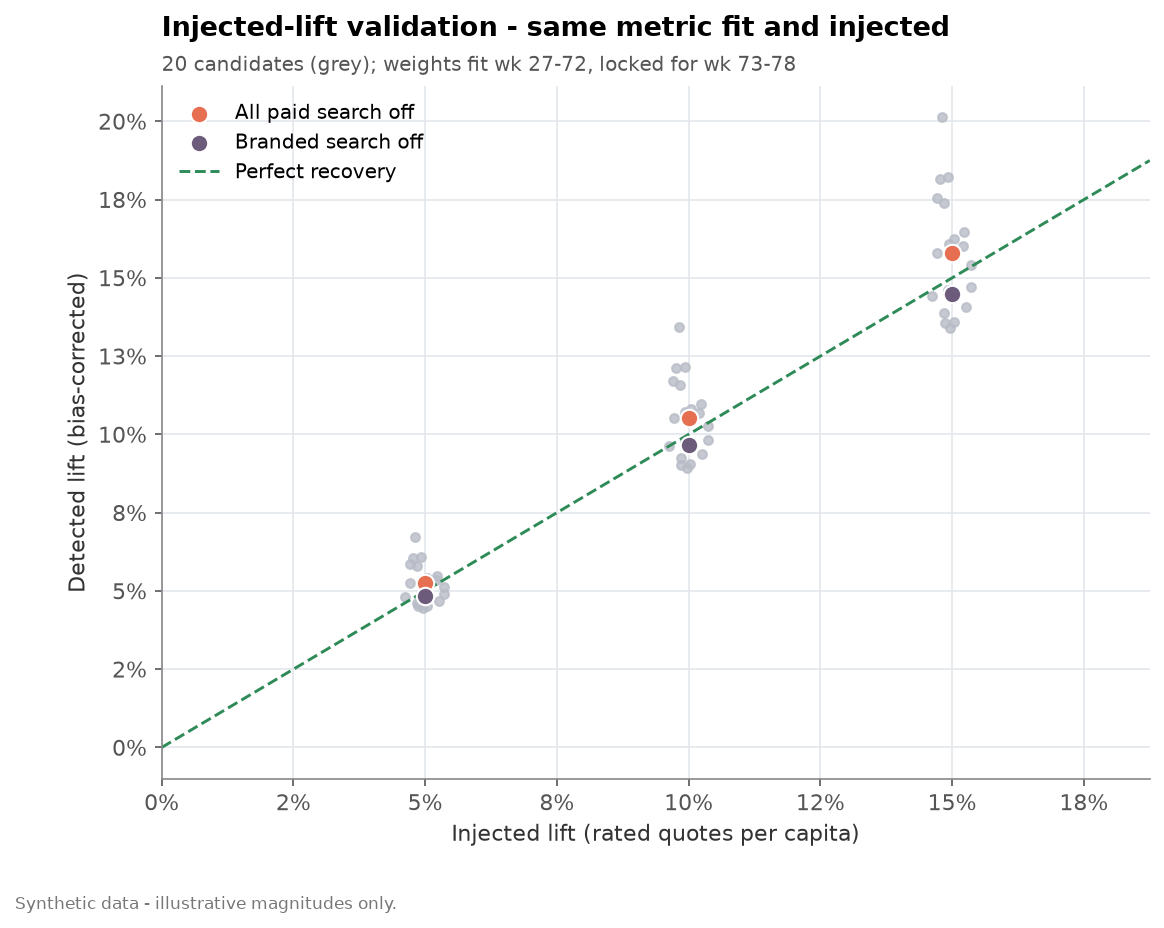

In [4]:
show("01_design_map", "search", 750); show("02_county_mde", "search"); show("03_injected_lift", "search")

## 2. Balance
With one or two counties per arm perfect demographic balance against the pool is impossible; what matters is that the synthetic
control matches the outcome path. The SMD chart shows both views.

In [5]:
des["balance"].filter(like="smd_synth").round(2)

,smd_synth_median_hh_income,smd_synth_pct_bachelors,smd_synth_density,smd_synth_homeowner_rate,smd_synth_median_age,smd_synth_pre_rated_pc,smd_synth_pre_sales_pc,smd_synth_pre_close_rate,smd_synth_pre_paid_share_rated,smd_synth_pre_brand_spend_pc
unit,,,,,,,,,,
all_search,-0.0600,-0.3100,-1.5400,1.1800,1.5800,-0.0100,-0.1700,-1.5600,0.9700,-0.1000
branded_only,-0.1200,-0.2200,-1.4300,1.0100,1.7500,-0.0700,-0.2900,-2.3100,-0.3700,0.3300
control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bau_pool_mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


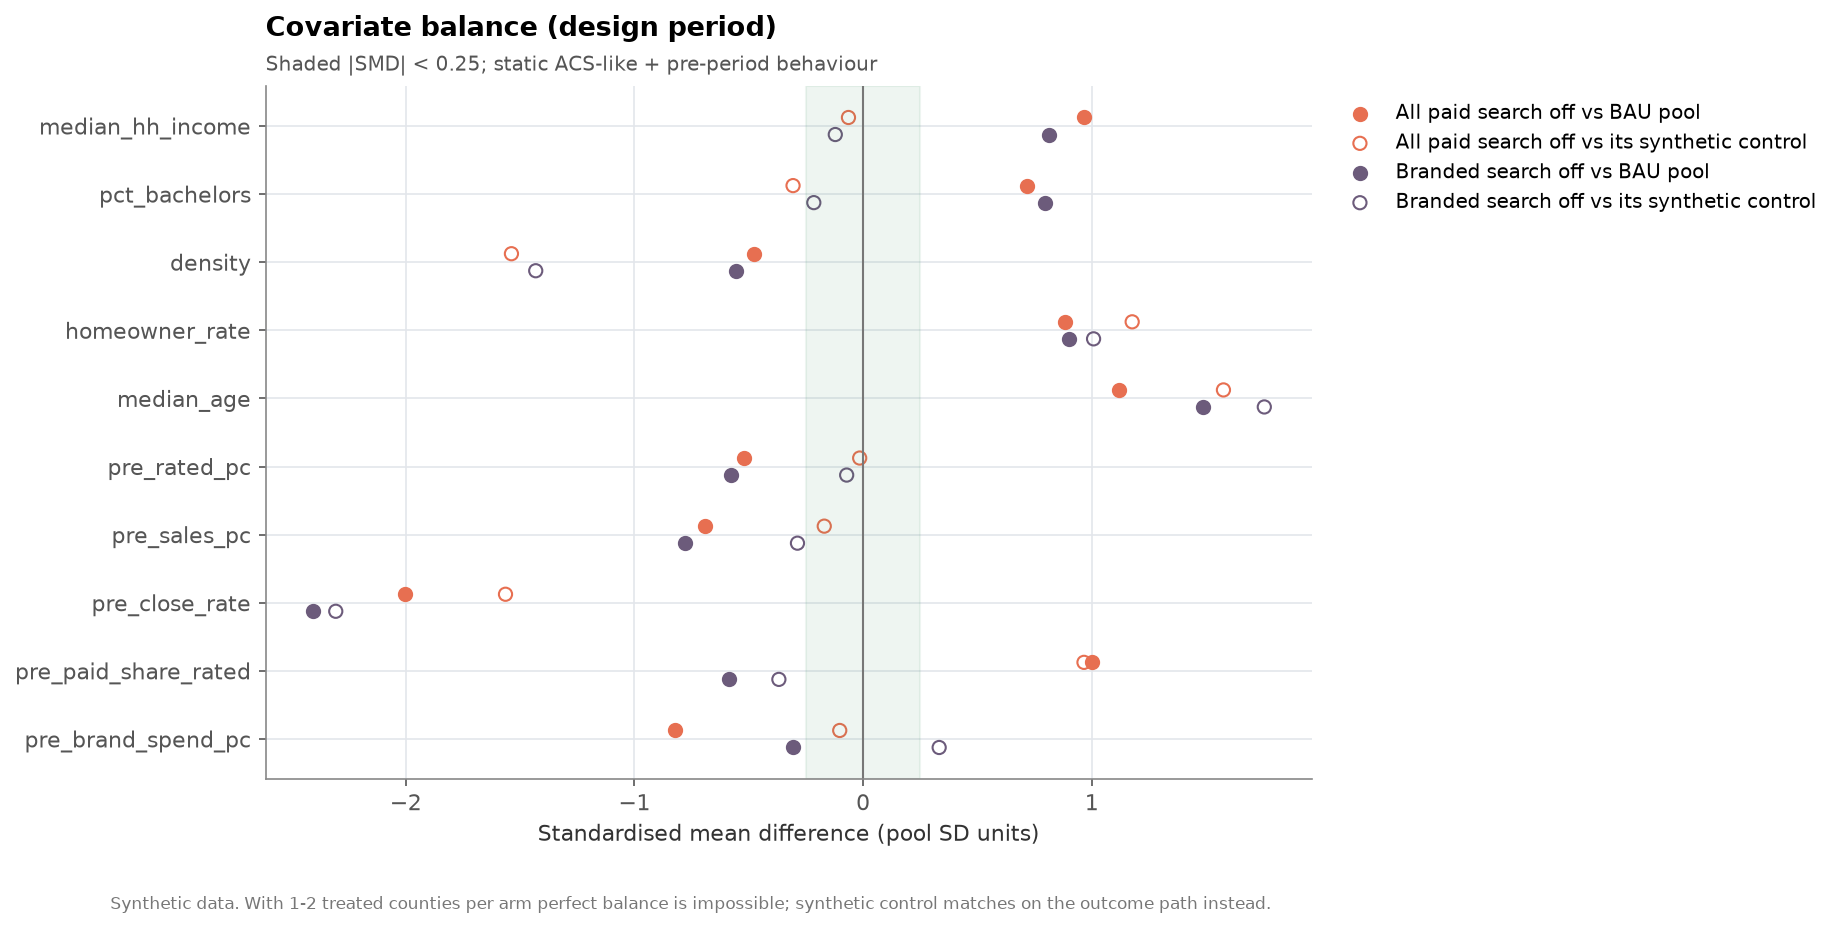

In [6]:
show("04_balance", "search")

## 3. Run the dark-out and read it out
`run()` applies the design via the scenario runner (true adstock + Hill response; the pre-period is asserted unchanged) and runs:
* ratio DiD vs the control county,
* **OLS DiD with unit + week FE** — cluster-robust SE reported, but inference by donor permutation because one treated
  cluster makes cluster SEs anti-conservative,
* **BSTS / CausalImpact-style** counterfactual — significant only when the credible interval excludes 0,
* **synthetic control** with an in-space placebo p-value.

In [7]:
from incrlab.search.pipeline import run
o = run(s, make_figures=True, write=True, verbose=False)
o["estimates"][["arm", "metric", "method", "estimate", "ci_low", "ci_high", "p_value", "significant", "truth"]]

,arm,metric,method,estimate,ci_low,ci_high,p_value,significant,truth
0,all_search,qs,ratio_did,0.0812,0.0163,0.1469,0.0459,True,0.0814
1,all_search,qs,ols_fe,0.0924,-0.0287,0.2135,0.1818,False,0.0814
2,all_search,qs,bsts,0.0987,0.0395,0.1538,0.0100,True,0.0814
3,all_search,qs,synth_control,0.0975,0.0404,0.1546,0.0909,True,0.0814
4,all_search,rated,ratio_did,0.0929,0.0307,0.1536,0.0131,True,0.0932
5,all_search,rated,ols_fe,0.1047,-0.0398,0.2492,0.2727,False,0.0932
6,all_search,rated,bsts,0.0908,0.0297,0.1540,0.0200,True,0.0932
7,all_search,rated,synth_control,0.0881,0.0306,0.1456,0.3636,False,0.0932
8,all_search,sales,ratio_did,-0.1427,-0.3871,0.0692,0.2910,False,0.1110
9,all_search,sales,ols_fe,-0.1177,-0.3056,0.0703,0.4545,False,0.1110


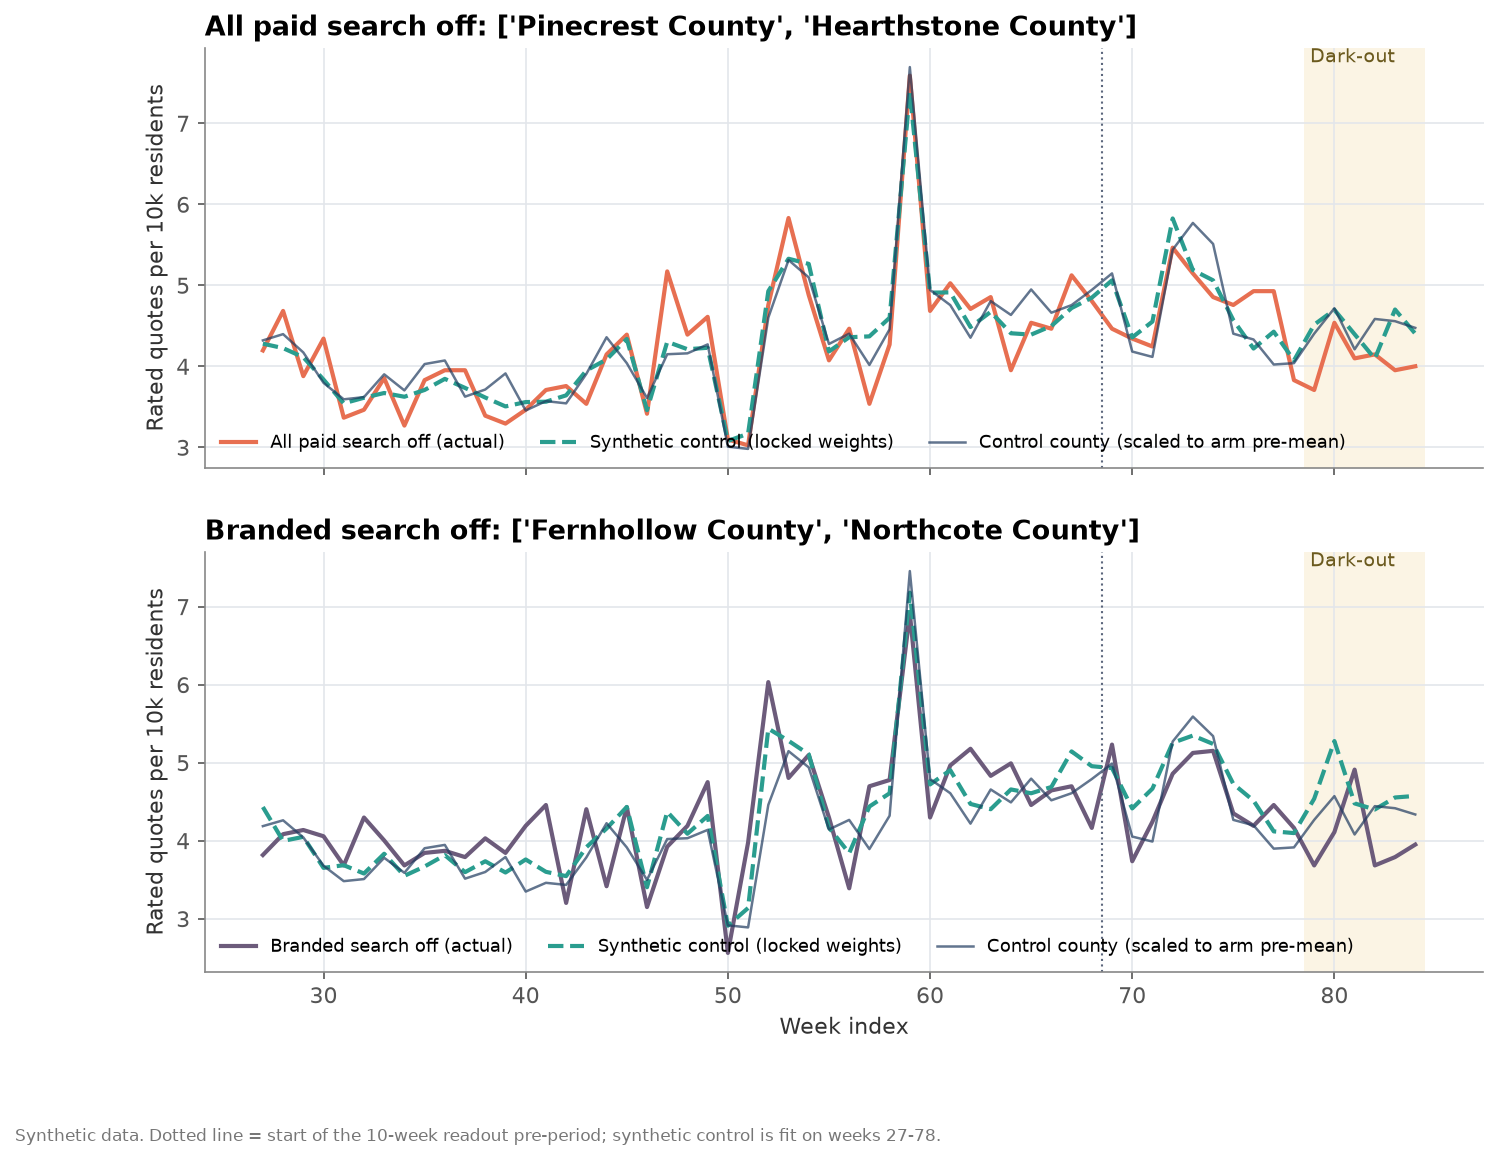

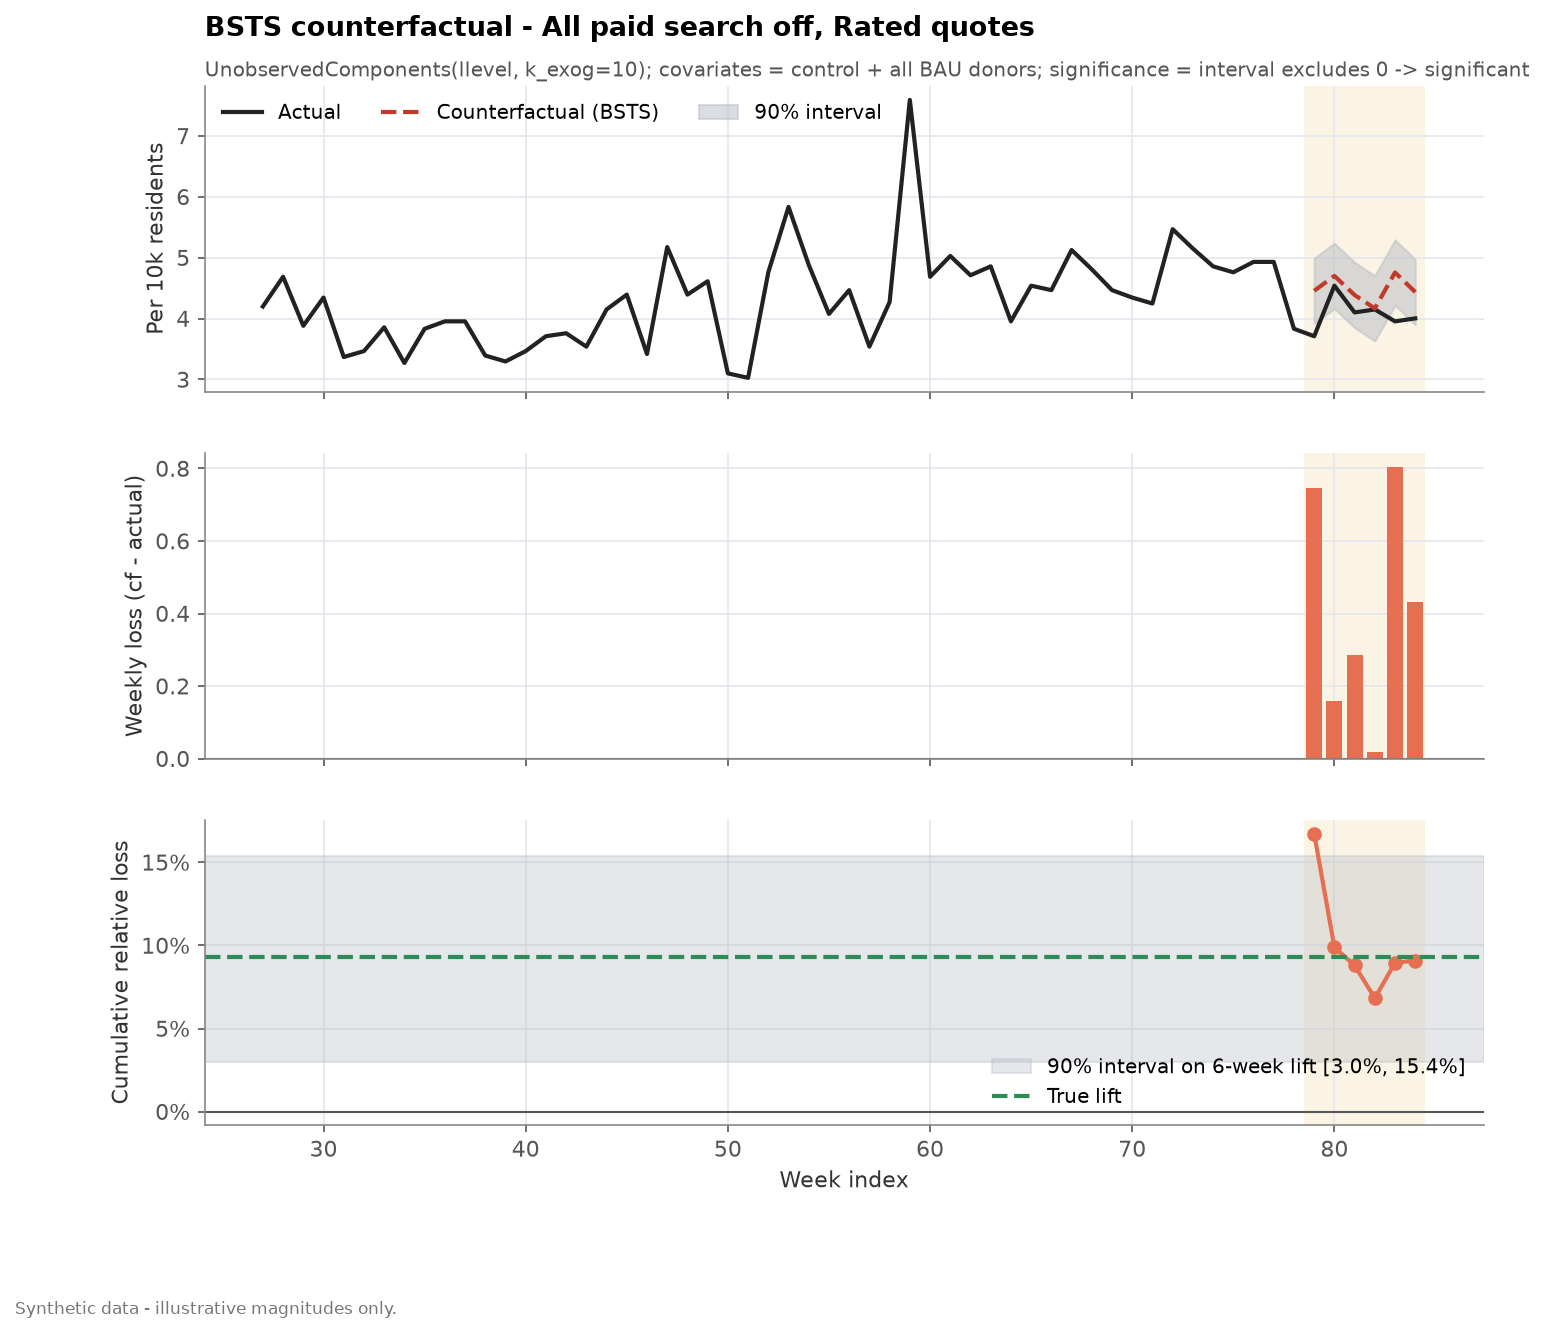

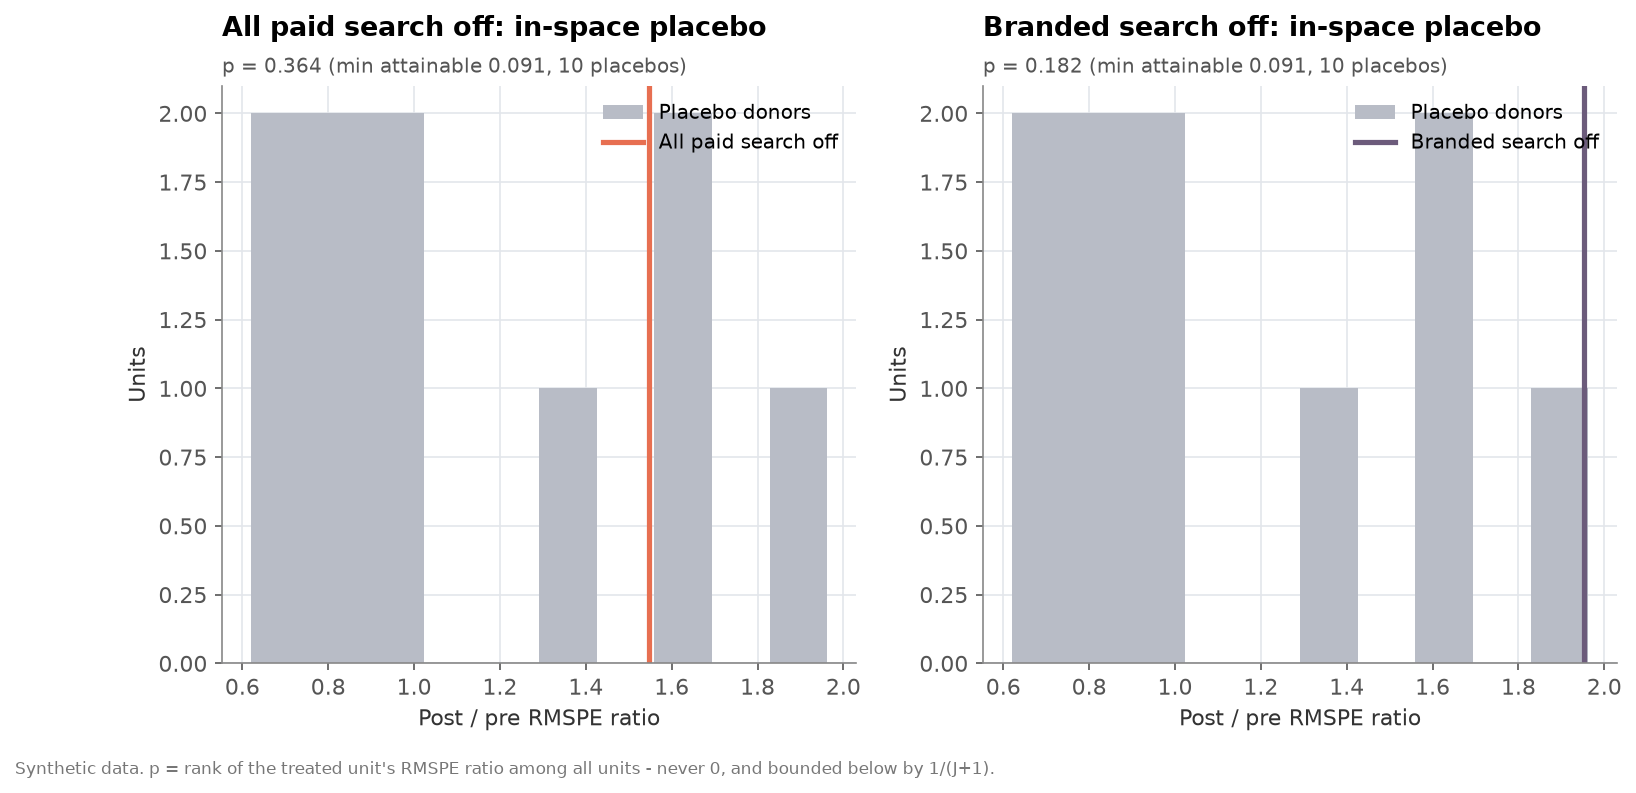

In [8]:
show("05_trends_sc", "search"); show("07_bsts_all_search_rated", "search"); show("06_placebo", "search")

In [9]:
o["triangulated"]

,test,arm,metric,method,estimate,ci_low,ci_high,ci_level,se,p_value,significant,truth,truth_key,truth_realized,units,notes,error_vs_truth,truth_in_ci
0,search,all_search,qs,triangulated,0.0935,0.0134,0.1736,0.9000,0.0487,0.0549,True,0.0814,scenario.search.all_search.qs.true_lift_pct,0.0847,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,0.0120,True
1,search,all_search,rated,triangulated,0.0913,0.0020,0.1805,0.9000,0.0542,0.0925,True,0.0932,scenario.search.all_search.rated.true_lift_pct,0.0965,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,-0.0020,True
2,search,all_search,sales,triangulated,-0.0446,-0.2399,0.1507,0.9000,0.1187,0.7072,False,0.1110,scenario.search.all_search.sales.true_lift_pct,0.0738,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,-0.1556,True
3,search,branded_only,qs,triangulated,0.0800,-0.0100,0.1699,0.9000,0.0547,0.1436,False,0.0284,scenario.search.branded_only.qs.true_lift_pct,0.0293,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,0.0516,True
4,search,branded_only,rated,triangulated,0.0981,-0.0110,0.2071,0.9000,0.0663,0.1391,False,0.0324,scenario.search.branded_only.rated.true_lift_pct,0.0259,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,0.0657,True
5,search,branded_only,sales,triangulated,0.0647,-0.1759,0.3054,0.9000,0.1463,0.6582,False,0.0397,scenario.search.branded_only.sales.true_lift_pct,0.0115,relative lift (positive = paid search contribu...,inverse-variance mean of the 4 methods; SE = R...,0.0251,True


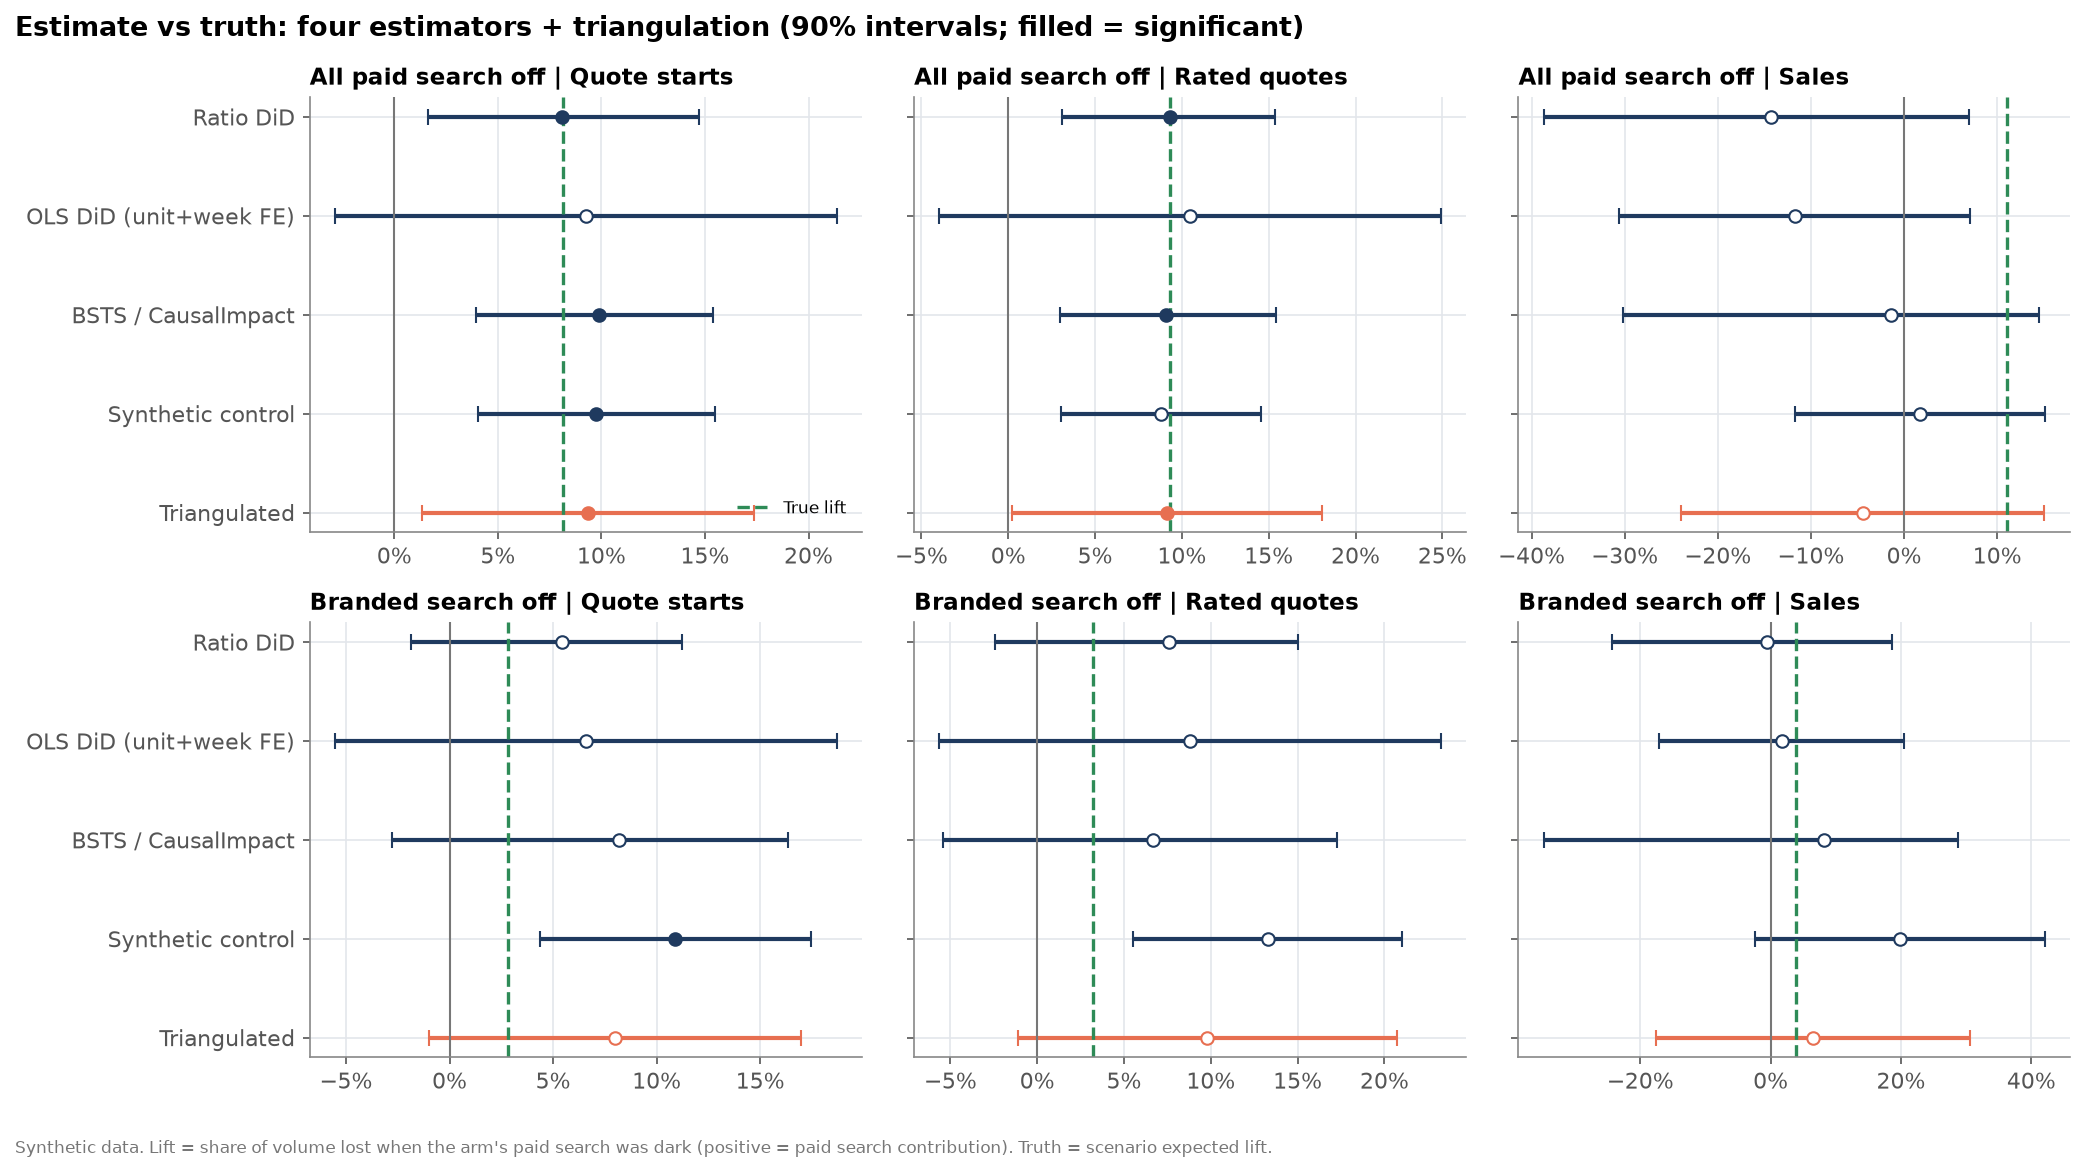

In [10]:
show("08_forest_truth", "search")

## 4. Power
Closed-form MDE (DiD with AR(1)), `TTestIndPower`, and a simulation on design-period data with an empirical-size check.
Rated quotes are decision-grade for the all-search arm; sales and the branded arm's lift are underpowered by design.

In [11]:
pd.DataFrame(o["power"]["table"])

,arm,metric,sigma_gap,rho,mde_closed_form,mde_ttest,observed_triangulated,weeks_needed_closed_form,weeks_needed_ttest,power_at_observed
0,all_search,qs,0.0698,0.0486,0.0941,0.0943,0.0935,8,7.6697,0.7956
1,all_search,rated,0.0747,0.0000,0.0959,0.1009,0.0913,9,9.0379,0.7649
2,all_search,sales,0.2358,0.0000,0.3028,0.3185,-0.0446,346,346.1362,0.1227
3,branded_only,qs,0.1012,0.0000,0.1299,0.1367,0.0800,20,20.5161,0.4551
4,branded_only,rated,0.1002,0.0340,0.1331,0.1354,0.0981,14,13.6458,0.5742
5,branded_only,sales,0.2507,0.0818,0.3495,0.3387,0.0647,219,186.2402,0.1358


In [12]:
pd.DataFrame(o["power"]["simulation"])

,arm,metric,power,empirical_size,n_sims,lift,n_pre,n_post
0,all_search,rated,0.3600,0.1533,300,0.0300,10,6
1,all_search,rated,0.4533,0.1533,300,0.0600,10,6
2,all_search,rated,0.7533,0.1533,300,0.1000,10,6
3,all_search,rated,1.0000,0.1533,300,0.1500,10,6
4,branded_only,rated,0.2533,0.2067,300,0.0300,10,6
5,branded_only,rated,0.4500,0.2067,300,0.0600,10,6
6,branded_only,rated,0.7667,0.2067,300,0.1000,10,6
7,branded_only,rated,0.9733,0.2067,300,0.1500,10,6


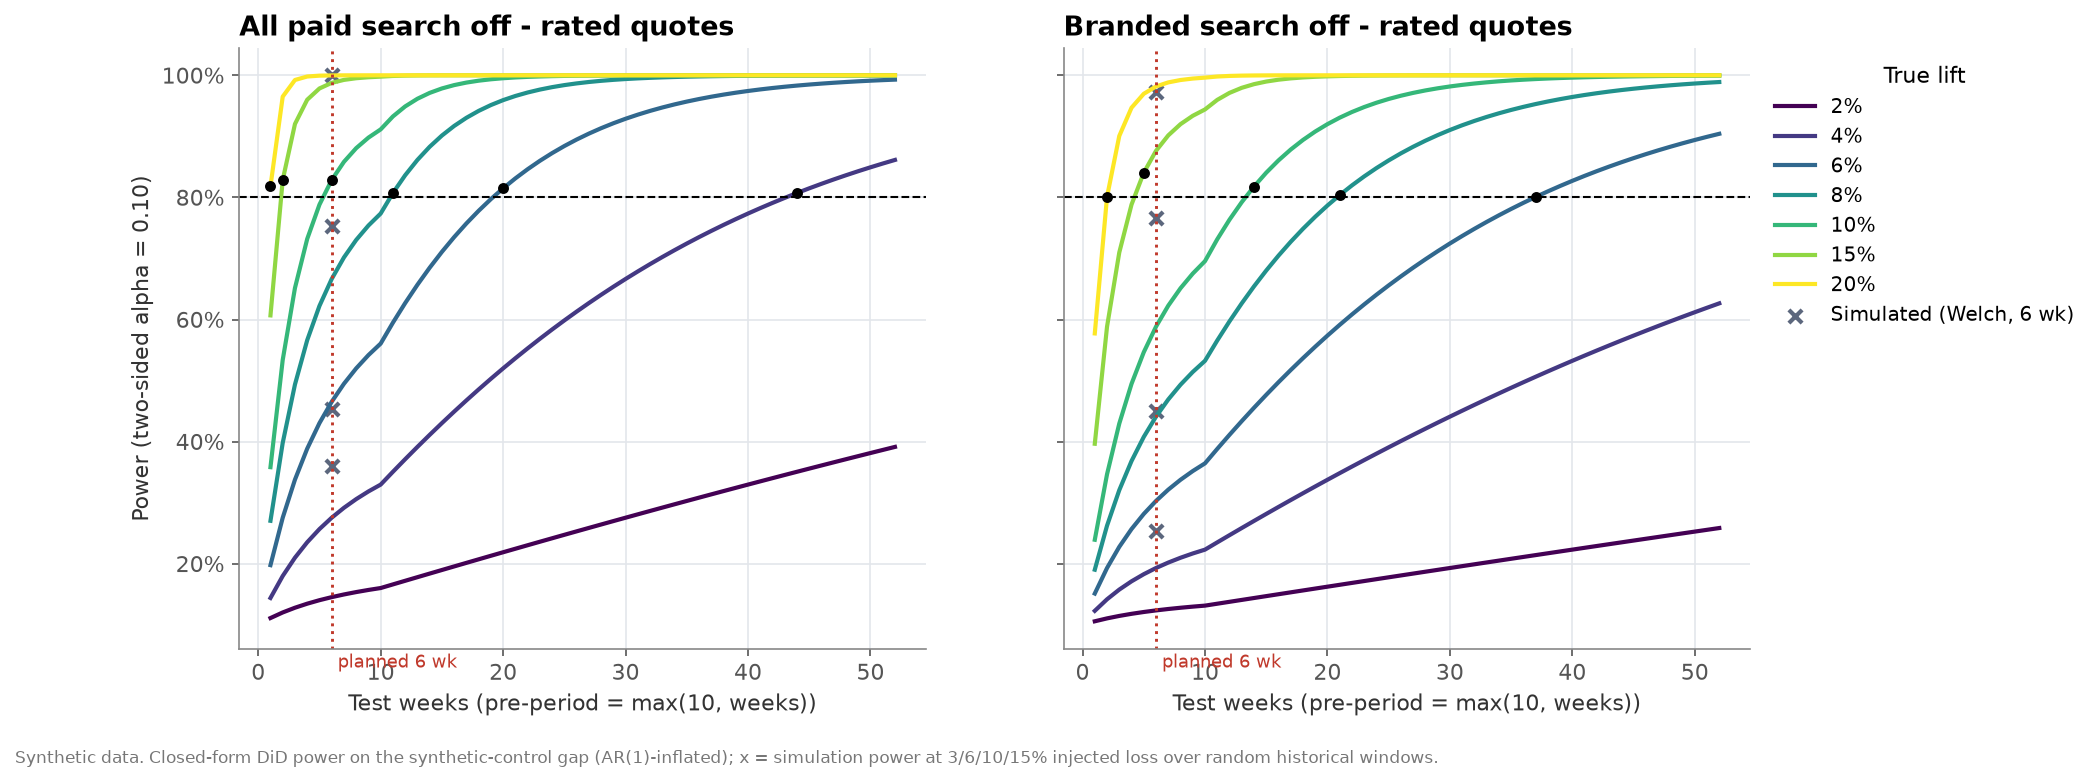

In [13]:
show("09_power", "search")

## 5. Cannibalisation: organic recapture
When paid search goes dark some lost paid last-touch conversions reappear as organic. Recapture = Δorganic / −Δpaid,
estimated with a per-source synthetic control and a week-bootstrap CI and compared to the generator's true recapture
(40% brand, 15% non-brand; the all-search arm blends the two).

In [14]:
o["recapture"]

,arm,stage,ref,delta_paid_per_wk,delta_organic_per_wk,recapture,ci_low,ci_high,se,truth
0,all_search,qs,synthetic,-34.7710,6.6046,0.1899,0.0714,0.3037,0.0693,0.2571
1,all_search,qs,control,-35.5537,7.6163,0.2142,0.0997,0.3389,0.0724,0.2571
2,all_search,rated,synthetic,-26.3462,4.2616,0.1618,0.0344,0.2988,0.0791,0.2571
3,all_search,rated,control,-26.3414,4.6833,0.1778,0.0516,0.3225,0.0833,0.2571
4,all_search,sales,synthetic,-2.2282,-0.0146,-0.0065,-0.3160,0.3067,0.1945,0.2608
5,all_search,sales,control,-2.6171,0.2634,0.1007,-0.1334,0.3648,0.1595,0.2608
6,branded_only,qs,synthetic,-11.4736,2.7741,0.2418,0.0234,0.5077,0.1480,0.4000
7,branded_only,qs,control,-11.5948,3.5659,0.3075,0.0151,0.6388,0.1868,0.4000
8,branded_only,rated,synthetic,-8.6544,2.9876,0.3452,0.1075,0.6277,0.1587,0.4000
9,branded_only,rated,control,-8.3743,3.3311,0.3978,0.0386,0.7651,0.2216,0.4000


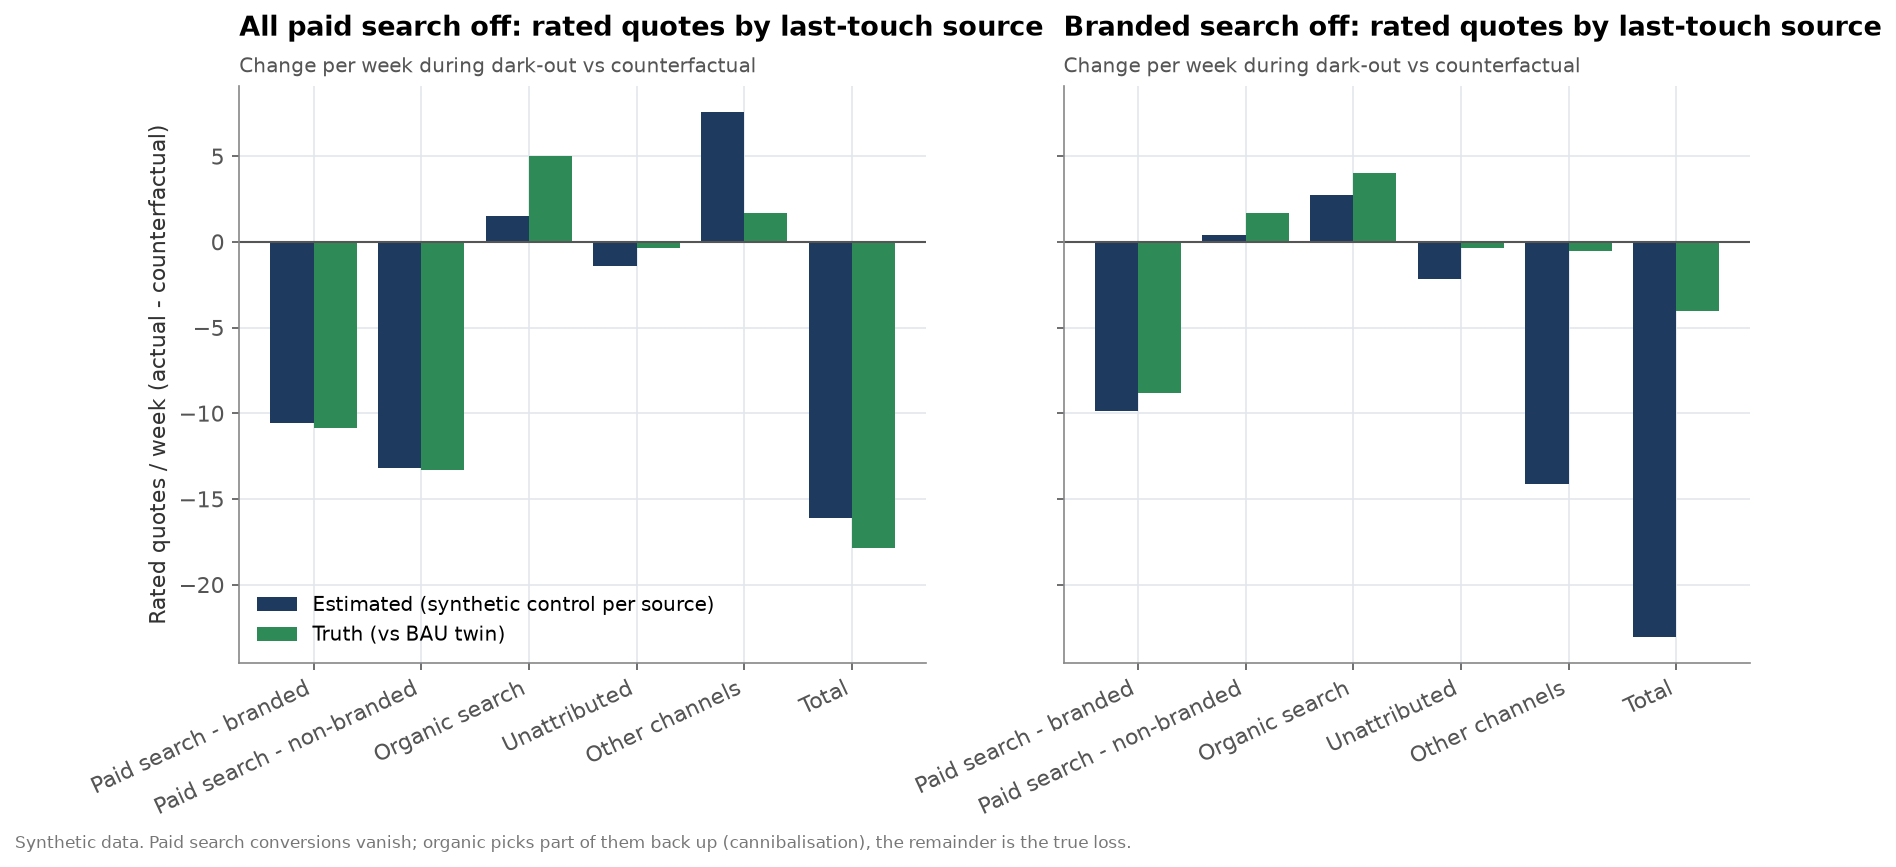

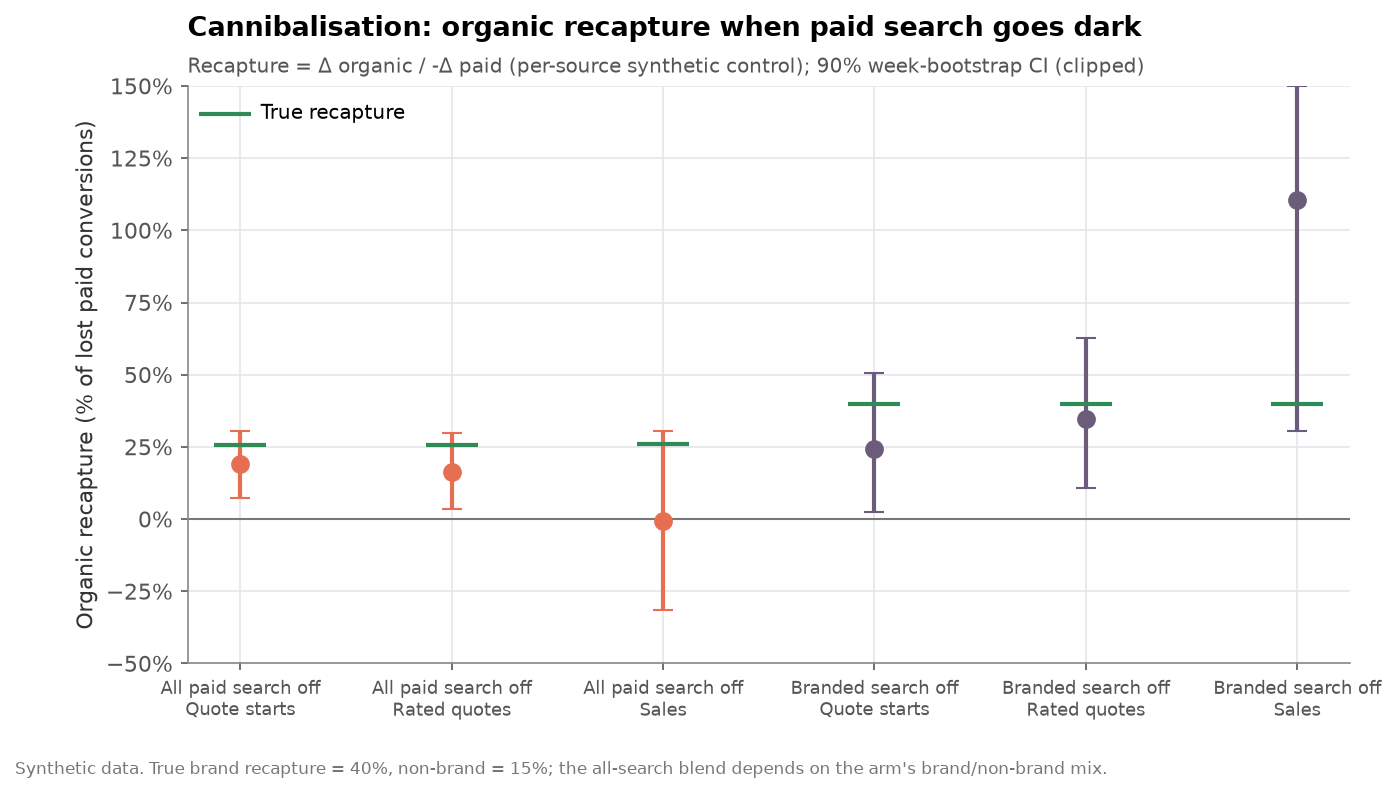

In [15]:
show("10_source_decomposition", "search"); show("11_recapture", "search")

## 6. Economics and guardrail
Incremental cost per rated quote / sale vs last-touch cost-per, plus the traffic guardrail (max 10% site-visit loss).

In [16]:
o["economics"]["table"]

,arm,metric,spend_removed_est,spend_removed_true,incremental_est,incremental_se,incremental_true,incr_cost_per_est,incr_cost_per_ci_low,incr_cost_per_ci_high,incr_cost_per_true,last_touch_cost_per,last_touch_share_pre,attribution_overclaim
0,all_search,qs,"13,740.4822","13,740.4822",156.0194,81.2905,128.9530,88.0691,47.4251,615.9308,106.5542,75.3395,0.1372,1.4676
1,all_search,rated,"13,740.4822","13,740.4822",100.6350,59.8113,98.3532,136.5378,69.0421,"6,095.6106",139.7055,97.8662,0.1564,1.7132
2,all_search,sales,"13,740.4822","13,740.4822",-4.8256,12.8449,12.2803,NaN,842.8487,inf,"1,118.9026","1,178.3095",0.1404,NaN
3,branded_only,qs,"3,611.5544","3,611.5544",118.0101,80.6843,40.2475,30.6038,14.4045,inf,89.7337,59.0040,0.0475,0.5939
4,branded_only,rated,"3,611.5544","3,611.5544",98.2807,66.4462,30.9198,36.7473,17.3988,inf,116.8039,77.3608,0.0528,0.5383
5,branded_only,sales,"3,611.5544","3,611.5544",5.9516,13.4519,3.9415,606.8247,128.6257,inf,916.2796,773.6076,0.0584,0.9029


In [17]:
o["guardrail"]

,arm,metric,estimate,ci_low,ci_high,p_value,truth,breach,threshold
0,all_search,visits,0.1271,0.0807,0.1736,0.0909,0.1390,True,0.1000
1,branded_only,visits,0.0966,0.0498,0.1434,0.0909,0.0600,False,0.1000


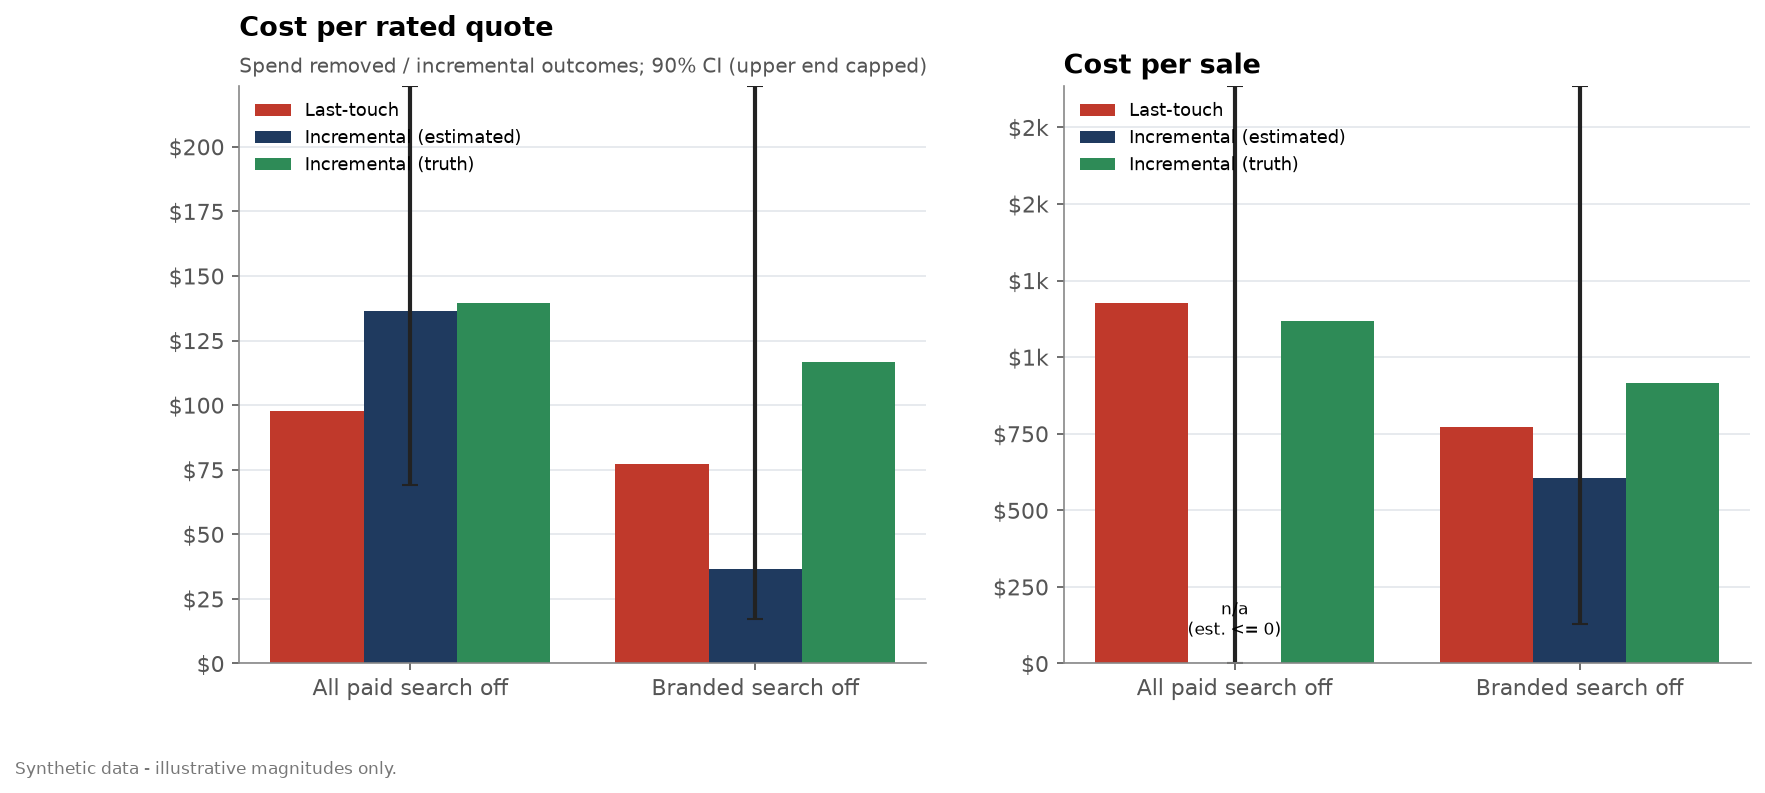

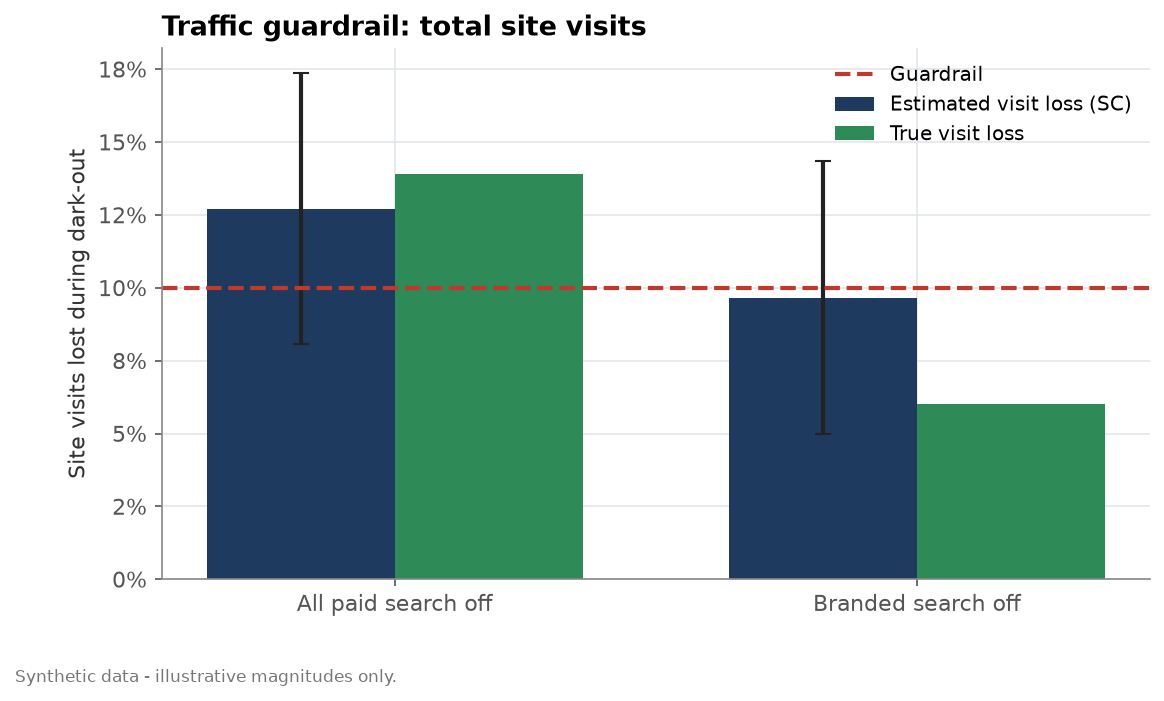

In [18]:
show("12_cost_per", "search"); show("13_guardrail", "search")

In [19]:
print(json.dumps(o["economics"]["incremental_per_dollar"], indent=1, default=float))

{
 "search_brand": {
  "spend": 3611.5543521519053,
  "window": [
   79,
   84
  ],
  "qs": 0.03267570049926636,
  "qs_se": 0.02234059945388478,
  "qs_truth": 0.011144084612345836,
  "rated": 0.027212858248287734,
  "rated_se": 0.018398240055822798,
  "rated_truth": 0.008561356788754864,
  "sales": 0.0016479223283783026,
  "sales_se": 0.0037246940845480016,
  "sales_truth": 0.0010913699860659746,
  "source": "branded_only arm (brand paused)",
  "notes": "incremental outcomes per $1 of paid search spend removed during the test window"
 },
 "search_nonbrand": {
  "spend": 10180.051006813428,
  "window": [
   79,
   84
  ],
  "qs": 0.0038977998092335465,
  "qs_se": 0.011172100784939642,
  "qs_truth": 0.008285874384814377,
  "rated": 0.00036792583910862185,
  "rated_se": 0.008713504445286546,
  "rated_truth": 0.0063182637690790714,
  "sales": -0.0010503822150471774,
  "sales_se": 0.001813587043828038,
  "sales_truth": 0.0007722286971221168,
  "source": "all_search arm minus brand effect sc

## 7. Truth vs estimate, recommendation, readout

In [20]:
o["truth_table"][["quantity", "estimate_fmt", "ci_fmt", "truth_fmt", "error_fmt"]]

,quantity,estimate_fmt,ci_fmt,truth_fmt,error_fmt
0,"Lift, All paid search off, quote starts (trian...",9.3%,"[1.3%, 17.4%]",8.1%,+1.2%
1,"Lift, All paid search off, rated quotes (trian...",9.1%,"[0.2%, 18.0%]",9.3%,-0.2%
2,"Lift, All paid search off, sales (triangulated)",-4.5%,"[-24.0%, 15.1%]",11.1%,-15.6%
3,"Lift, Branded search off, quote starts (triang...",8.0%,"[-1.0%, 17.0%]",2.8%,+5.2%
4,"Lift, Branded search off, rated quotes (triang...",9.8%,"[-1.1%, 20.7%]",3.2%,+6.6%
5,"Lift, Branded search off, sales (triangulated)",6.5%,"[-17.6%, 30.5%]",4.0%,+2.5%
6,"Organic recapture, All paid search off, quote ...",19.0%,"[7.1%, 30.4%]",25.7%,-6.7%
7,"Organic recapture, All paid search off, rated ...",16.2%,"[3.4%, 29.9%]",25.7%,-9.5%
8,"Organic recapture, Branded search off, quote s...",24.2%,"[2.3%, 50.8%]",40.0%,-15.8%
9,"Organic recapture, Branded search off, rated q...",34.5%,"[10.8%, 62.8%]",40.0%,-5.5%


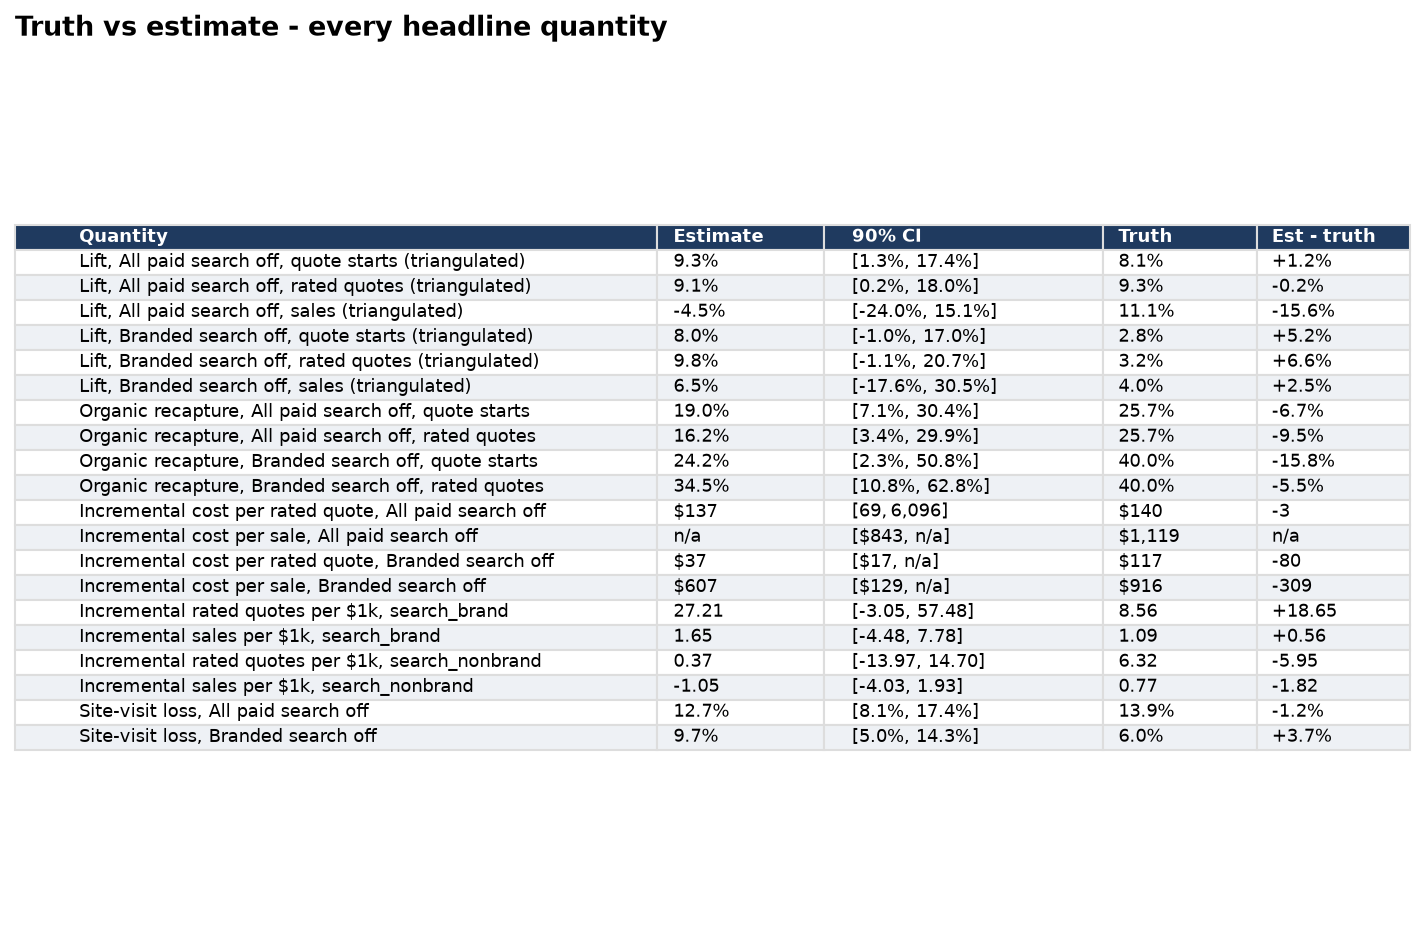

In [21]:
show("14_truth_table", "search")

In [22]:
for line in o["recommendation"]["lines"]:
    print("-", line)
display(Markdown((ROOT / "reports/readouts/search.md").read_text()))

- All paid search is incremental on rated quotes: 9.1% of rated quotes lost when dark (90% CI 0.2% to 18.0%); incremental cost per rated quote $137 vs $98 last-touch.
- Sales read is inconclusive (est. -4.5%, CI -24.0% to +15.1%; 6 weeks of binds cannot resolve a ~10% lift) - do not cut search on the sales number alone.
- Branded search is heavily cannibalised: organic recaptures ~35% (CI 11%-63%) of lost branded rated quotes. Move brand to a defensive bidding policy (bid only where competitors are present on brand terms / lower caps) and re-test with a powered design.
- Incremental rated quotes per $1k: branded 27.2 vs non-branded 0.4 (SE 18.4 / 8.7) -> feed both, with SEs, to the MMM as calibration priors.
- Traffic guardrail (10% max visit loss) breached in: all_search.
- The branded arm's rated-quote MDE (13% at 80% power) is far above a plausible branded lift (~3%): its lift read is directional; the cannibalisation (source-level) read is the decision-grade output of that arm.


# Paid Search geo dark-out — executive readout (synthetic)

*Module 2 of incrementality-lab. Synthetic data with known ground truth; magnitudes are illustrative.
All intervals are two-sided 90%. Lift = share of volume lost while paid search was dark (positive = paid search contribution).*

## Question
How much of paid search is truly incremental, and how much branded search merely buys conversions that organic
search would have delivered anyway (cannibalisation)?

## Design (selected by the pipeline from 20 candidate units, data through week 78)
| Arm | Counties | Paused |
|---|---|---|
| All paid search off | Pinecrest County + Hearthstone County | branded + non-branded |
| Branded search off | Fernhollow County + Northcote County | branded only |
| Control | Ironwood County | nothing (ratio-DiD comparator) |
| BAU donors | 9 counties | nothing (synthetic control / BSTS / FE-DiD pool) |

Weeks 79–84 dark (6 wk); readout pre-period weeks 69–78; synthetic control fit on weeks
27–78. Arms were chosen to maximise expected power (rated quotes + sales) under a recovery gate
on +5/10/15% injected lifts measured on the **same** metric used for fitting.

## Results — triangulated lift vs truth
| Arm | Metric | Lift | 90% CI | Methods significant | Truth | MDE (80% power) |
|---|---|---|---|---|---|---|
| All paid search off | quote starts | **9.3%** | [1.3%, 17.4%] | 3/4 | 8.1% | 9% |
| All paid search off | rated quotes | **9.1%** | [0.2%, 18.0%] | 2/4 | 9.3% | 10% |
| All paid search off | sales | **-4.5%** | [-24.0%, 15.1%] | 0/4 | 11.1% | 30% |
| Branded search off | quote starts | **8.0%** | [-1.0%, 17.0%] | 1/4 | 2.8% | 13% |
| Branded search off | rated quotes | **9.8%** | [-1.1%, 20.7%] | 0/4 | 3.2% | 13% |
| Branded search off | sales | **6.5%** | [-17.6%, 30.5%] | 0/4 | 4.0% | 35% |

Methods: ratio DiD vs control, OLS DiD with unit + week fixed effects (inference by donor permutation — cluster-robust
SE with one treated cluster is anti-conservative), BSTS counterfactual on all donors (significance only when its interval
excludes 0), synthetic control with in-space placebo p (never below 1/(J+1)).

## Cannibalisation — organic recapture
| Arm | Stage | Δ paid LT / wk | Δ organic LT / wk | Recapture [90% CI] | Truth |
|---|---|---|---|---|---|
| Branded search off | quote starts | -11.5 | +2.8 | **24%** [2%, 51%] | 40% |
| Branded search off | rated quotes | -8.7 | +3.0 | **35%** [11%, 63%] | 40% |
| All paid search off | quote starts | -34.8 | +6.6 | **19%** [7%, 30%] | 26% |
| All paid search off | rated quotes | -26.3 | +4.3 | **16%** [3%, 30%] | 26% |

## Efficiency — incremental vs last-touch
| Arm | Per | Last-touch | Incremental (est.) [90% CI] | Incremental (truth) |
|---|---|---|---|---|
| All paid search off | rated quote | $98 | **$137** [$69, $6,096] | $140 |
| Branded search off | rated quote | $77 | **$37** [$17, n/a] | $117 |
| All paid search off | sale | $1,178 | **n/a** [$843, n/a] | $1,119 |
| Branded search off | sale | $774 | **$607** [$129, n/a] | $916 |

MMM calibration (`extra.incremental_per_dollar`): branded **27.2** incremental rated quotes per $1k
(SE 18.4; truth 8.6); non-branded
**0.4** (SE 8.7; truth 6.3).

Traffic guardrail (≤10% visit loss): all-search 12.7% (truth 13.9%),
branded-only 9.7% (truth 6.0%).

## Recommendation
- All paid search is incremental on rated quotes: 9.1% of rated quotes lost when dark (90% CI 0.2% to 18.0%); incremental cost per rated quote $137 vs $98 last-touch.
- Sales read is inconclusive (est. -4.5%, CI -24.0% to +15.1%; 6 weeks of binds cannot resolve a ~10% lift) - do not cut search on the sales number alone.
- Branded search is heavily cannibalised: organic recaptures ~35% (CI 11%-63%) of lost branded rated quotes. Move brand to a defensive bidding policy (bid only where competitors are present on brand terms / lower caps) and re-test with a powered design.
- Incremental rated quotes per $1k: branded 27.2 vs non-branded 0.4 (SE 18.4 / 8.7) -> feed both, with SEs, to the MMM as calibration priors.
- Traffic guardrail (10% max visit loss) breached in: all_search.
- The branded arm's rated-quote MDE (13% at 80% power) is far above a plausible branded lift (~3%): its lift read is directional; the cannibalisation (source-level) read is the decision-grade output of that arm.

## Caveats
- Synthetic world; true effects come from the generator's adstock + Hill response, not from this analysis.
- One treated unit per arm: every p-value is rank-based and bounded below by 1/(donors+1).
- Six weeks of binds cannot resolve sales lifts near 10% — sales reads are directional; rated quotes are the decision KPI.
- 100% of the 20 headline quantities have the truth inside their 90% interval (see `reports/figures/search/14_truth_table.png`).


**Take-aways**
* All paid search is incremental on quote starts and rated quotes; the estimate sits close to truth and its interval excludes 0.
* Six weeks of sales cannot resolve the effect — say so rather than cutting spend on a noisy sales read.
* Branded search is substantially cannibalised by organic; the branded arm's *lift* is underpowered, its recapture read is useful.
* Incremental-per-dollar figures (with SEs) go to `extra.incremental_per_dollar` for MMM calibration.